# Real networks: broader seed-score ranges

Analysis of the overnight score-range collection (17 November 2026).

**Questions:** Does broader sampling reveal a performance–score relationship on
native real pairs? Do synthetic selectors transfer? Which A-only features and
selection rules help within a fixed graph pair and seed budget?

This notebook reads saved CSV/JSON data and produces tables and figures. It does
not collect outcomes, refit selectors, or run matching. The synthetic ensemble is
an equal mean of compatible saved predictors (nine for FAQ/percolation; six for
real GOAT at regularizer 300). It is not a model trained on real data. Every
individual source prediction is analyzed separately in section 5.

Accuracy is the fraction of the fixed held-out test vertices matched to their
true counterparts. These vertices were excluded from seed selection.

In [1]:
import os
import sys
import tempfile
import importlib
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "sgm_matplotlib_cache"))
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "selection_rule_comparison").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from selection_rule_comparison import score_range_analysis as A
A = importlib.reload(A)

DATA_ROOT = ROOT / "selection_rule_comparison/data/score_range_collection"
EXPORT = ROOT / "selection_rule_comparison/data/score_range_analysis/real"
FIGURES = EXPORT / "figures"
FROZEN_REFERENCE = "er"  # Real-data reference; other frozen scores are reported separately.
data = A.load_collection(DATA_ROOT, kind="real", frozen_reference=FROZEN_REFERENCE)
assert data.banks.complete.all(), "Some evaluation blocks are incomplete."
mean = data.per_set("mean")
single = data.per_set("single")
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 24)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10})

def show(fig, name):
    A.save_figure(fig, FIGURES, name)
    plt.show()
    plt.close(fig)

print(f"{len(data.banks)} algorithm/bank combinations; {len(data.runs):,} evaluations; all complete.")
print("Reading saved outcomes only. Exports:", EXPORT)

60 algorithm/bank combinations; 19,900 evaluations; all complete.
Reading saved outcomes only. Exports: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/score_range_analysis/real


## 1. Inventory and a first descriptive summary

The same seed bank is evaluated by all three algorithms on each real pair/budget.
Each set has one percolation run, three FAQ/GOAT solver runs on the small pairs,
and two FAQ/GOAT runs on Wikipedia. Native B is fixed. All main plots average the
solver runs per set, so repeated runs do not appear as additional scatter points.

The full worm and LCC cases overlap; Enron windows and budgets also share graphs.
The table below is descriptive across banks, with no independent-replicate claim
or p-values. A policy "win" means more than 0.01 accuracy above the uniform mean.

In [2]:
display(data.banks.groupby("case", sort=False).agg(
    budgets=("budget", lambda s: sorted(s.unique())), seed_banks=("bank_id", "nunique"),
    n=("n", "first"), seed_sets=("sets", lambda s: int(s.sum()/3)),
    evaluations=("runs", "sum"), complete=("complete", "all")))

,budgets,seed_banks,n,seed_sets,evaluations,complete
case,,,,,,
enron_130_131,"[5, 10, 20]",3,145,450,3150,True
enron_130_132,"[5, 10, 20]",3,141,450,3150,True
enron_145_147,"[5, 10, 20]",3,104,450,3150,True
enron_160_162,"[5, 10, 20]",3,96,450,3150,True
worm,"[50, 100]",2,279,300,2100,True
worm_lcc,"[50, 100]",2,247,300,2100,True
worm_male,"[20, 40]",2,167,300,2100,True
wikipedia,"[10, 20]",2,1382,200,1000,True


In [3]:
coverage = A.coverage_table(mean)
scores = A.score_diagnostics(mean)
features = A.feature_diagnostics(mean)
policies = A.policy_table(data, mean)
sources = A.source_diagnostics(data, mean)
contrasts = A.contrast_table(data, mean)
convergence = A.convergence_table(data, mean)
summary = A.overview(scores, policies)
display(summary)

,banks,median_frozen_rho,median_learned_rho,positive_frozen_rho,positive_learned_rho,median_prediction_mae,median_prediction_bias,frozen_er_median_gain,frozen_er_wins_vs_random,learned_mean_median_gain,learned_mean_wins_vs_random
algorithm,,,,,,,,,,,
percolation,20,0.078,0.068,13,12,0.434,0.434,0.004,9,-0.003,7
faq,20,0.058,0.066,11,11,0.326,0.324,-0.008,6,-0.005,7
goat,20,-0.079,-0.003,8,9,0.179,0.133,0.001,7,0.013,10


## 2. Did the additional sets broaden score coverage?

Each row below is one graph/budget/algorithm. The span ratio is the full bank's
score range divided by the range among its 20 or 30 uniform controls. It is a
comparison with those sampled controls, not a bound on all possible random sets.

The heatmaps count evaluated sets in the eight equal-width frozen-score intervals
used during collection. Every row has its own interval bounds. The per-bank
`coverage.csv` inputs also record the other frozen and predicted-score axes. These counts
describe our deliberate sampling design, not a population distribution of seed sets.

,panel,algorithm,sets,random,frozen_min,frozen_max,frozen_span_ratio,predicted_span_ratio
0,Enron 130–131 · k=5,percolation,150,30,-1.632,9.462,4.435,2.557
1,Enron 130–131 · k=5,faq,150,30,-1.057,5.644,3.636,2.565
2,Enron 130–131 · k=5,goat,150,30,-1.147,3.764,3.425,2.302
3,Enron 130–131 · k=10,percolation,150,30,-2.054,7.448,3.110,2.110
4,Enron 130–131 · k=10,faq,150,30,-1.125,4.733,4.114,2.458
5,Enron 130–131 · k=10,goat,150,30,-1.195,3.087,2.446,2.932
6,Enron 130–131 · k=20,percolation,150,30,-2.193,4.655,1.904,1.737
7,Enron 130–131 · k=20,faq,150,30,-1.224,3.055,2.304,1.792
8,Enron 130–131 · k=20,goat,150,30,-1.400,2.302,2.134,2.229
9,Enron 130–132 · k=5,percolation,150,30,-1.622,8.815,3.660,2.006


Occupied target intervals with no selected set: 0


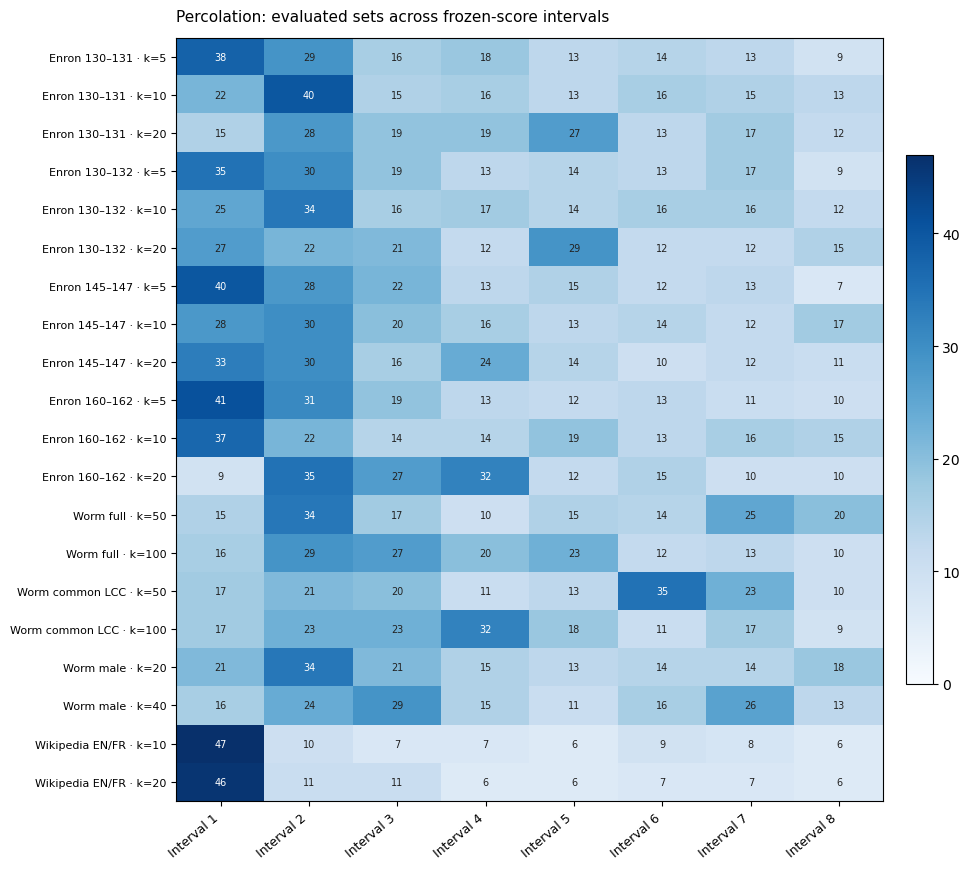

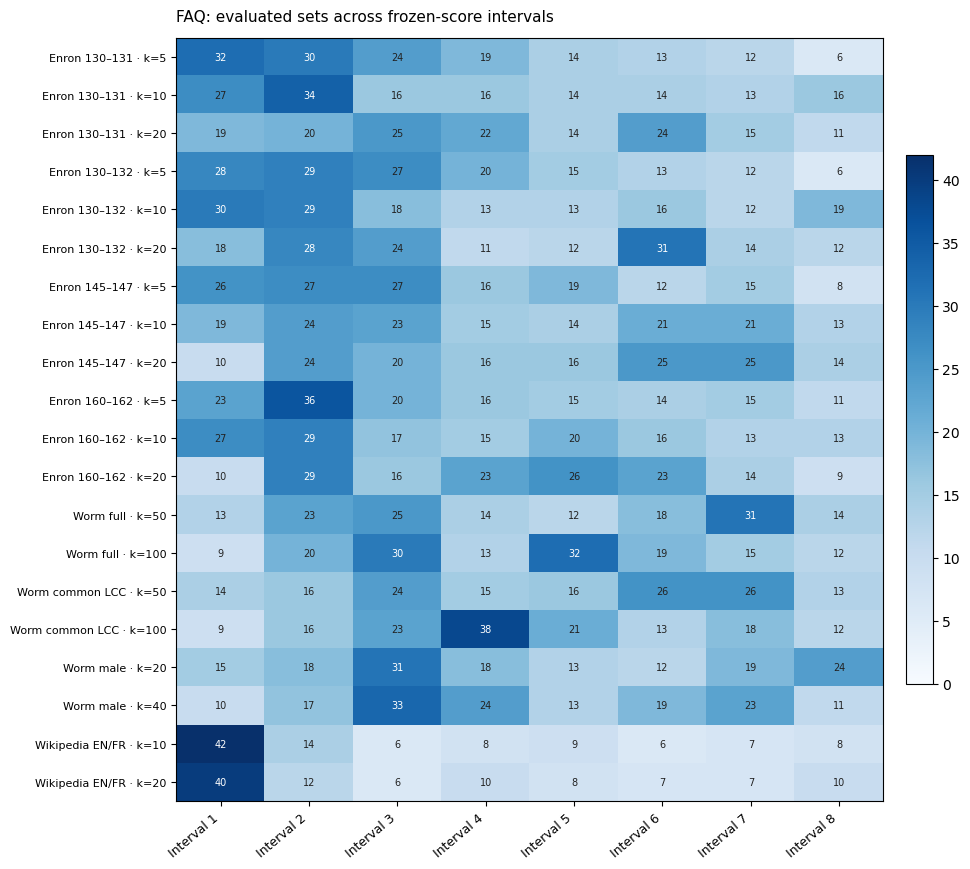

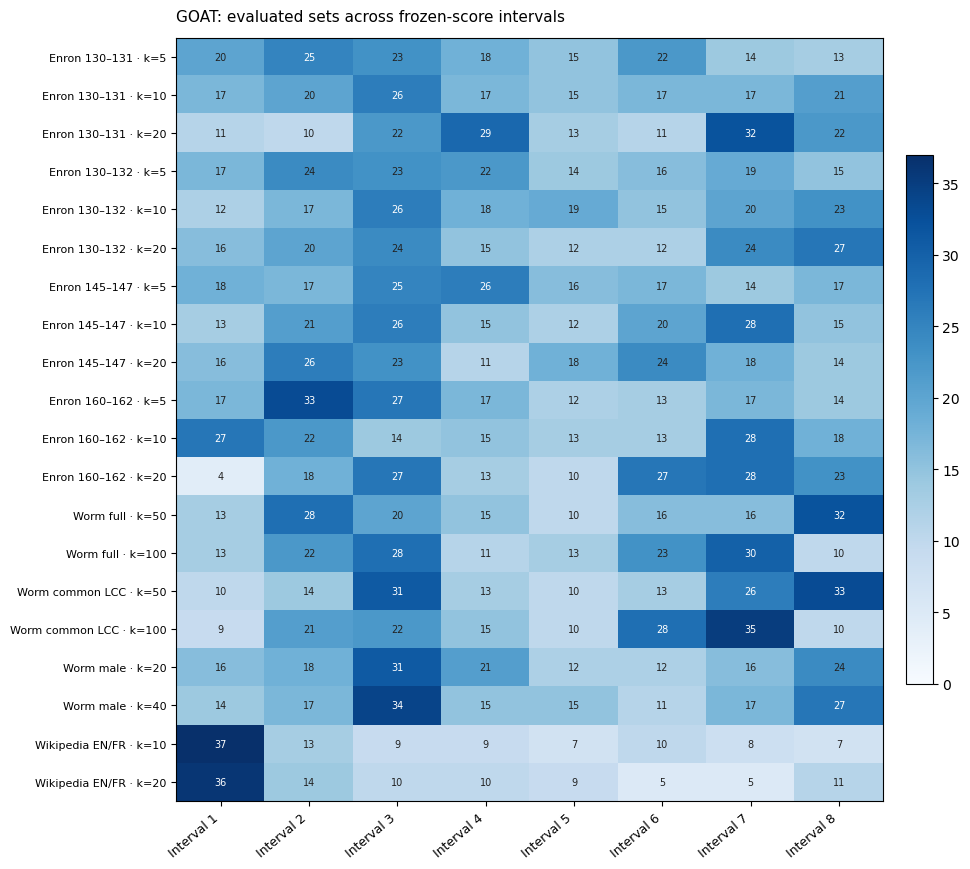

In [4]:
display(coverage[["panel", "algorithm", "sets", "random", "frozen_min", "frozen_max",
                  "frozen_span_ratio", "predicted_span_ratio"]])
occupied = data.coverage[data.coverage.available.gt(0)]
print("Occupied target intervals with no selected set:", int(occupied.selected.eq(0).sum()))
for algorithm in A.ALGORITHMS:
    show(A.plot_coverage(data, mean, algorithm), f"{algorithm}_score_coverage")

## 3. Frozen score and learned prediction on the same sets

Each row fixes pair and k. Columns pair a frozen-score view with a learned-prediction
view for each algorithm; both columns contain exactly the same evaluated sets.
The main frozen reference is ER for continuity with the original real-data plots;
set `FROZEN_REFERENCE` in setup to `cl` or `paper` and rerun to change it. Section 4
reports all three frozen scores irrespective of this display choice.

Colours identify primary sampling families. A rule can share a set with another
rule or family; named rule comparisons in section 5 use the full saved memberships.
Annotations show Spearman correlations across the full bank and uniform controls.
The grey dashed line on prediction panels is y=x for calibration, not a fitted
trend line. Frozen scores are weighted feature sums, not probabilities.

### wikipedia

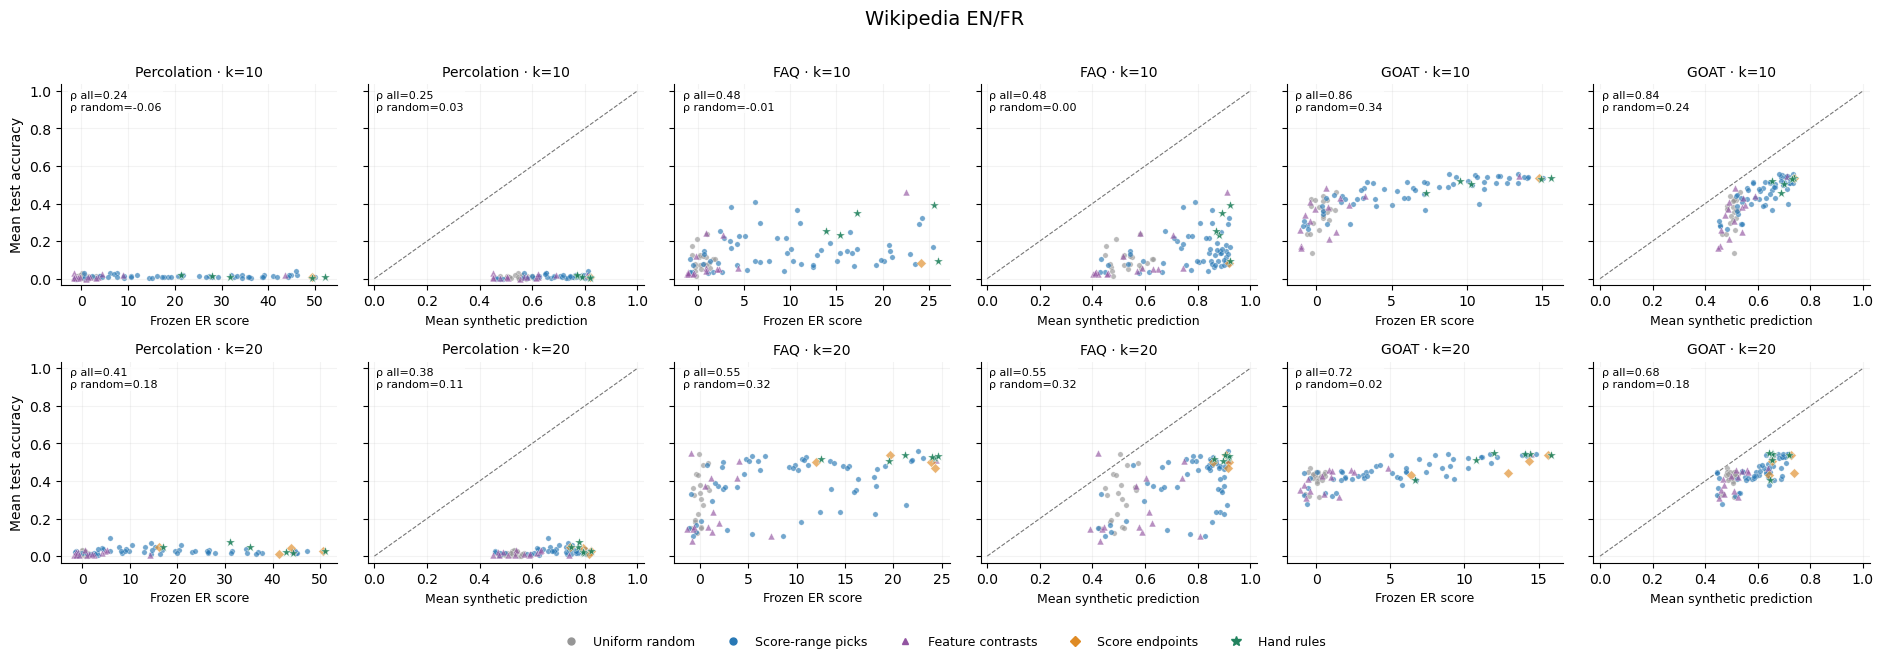

In [5]:
show(A.plot_real_scores(mean, "wikipedia"), "wikipedia_scores")

### enron 130 132

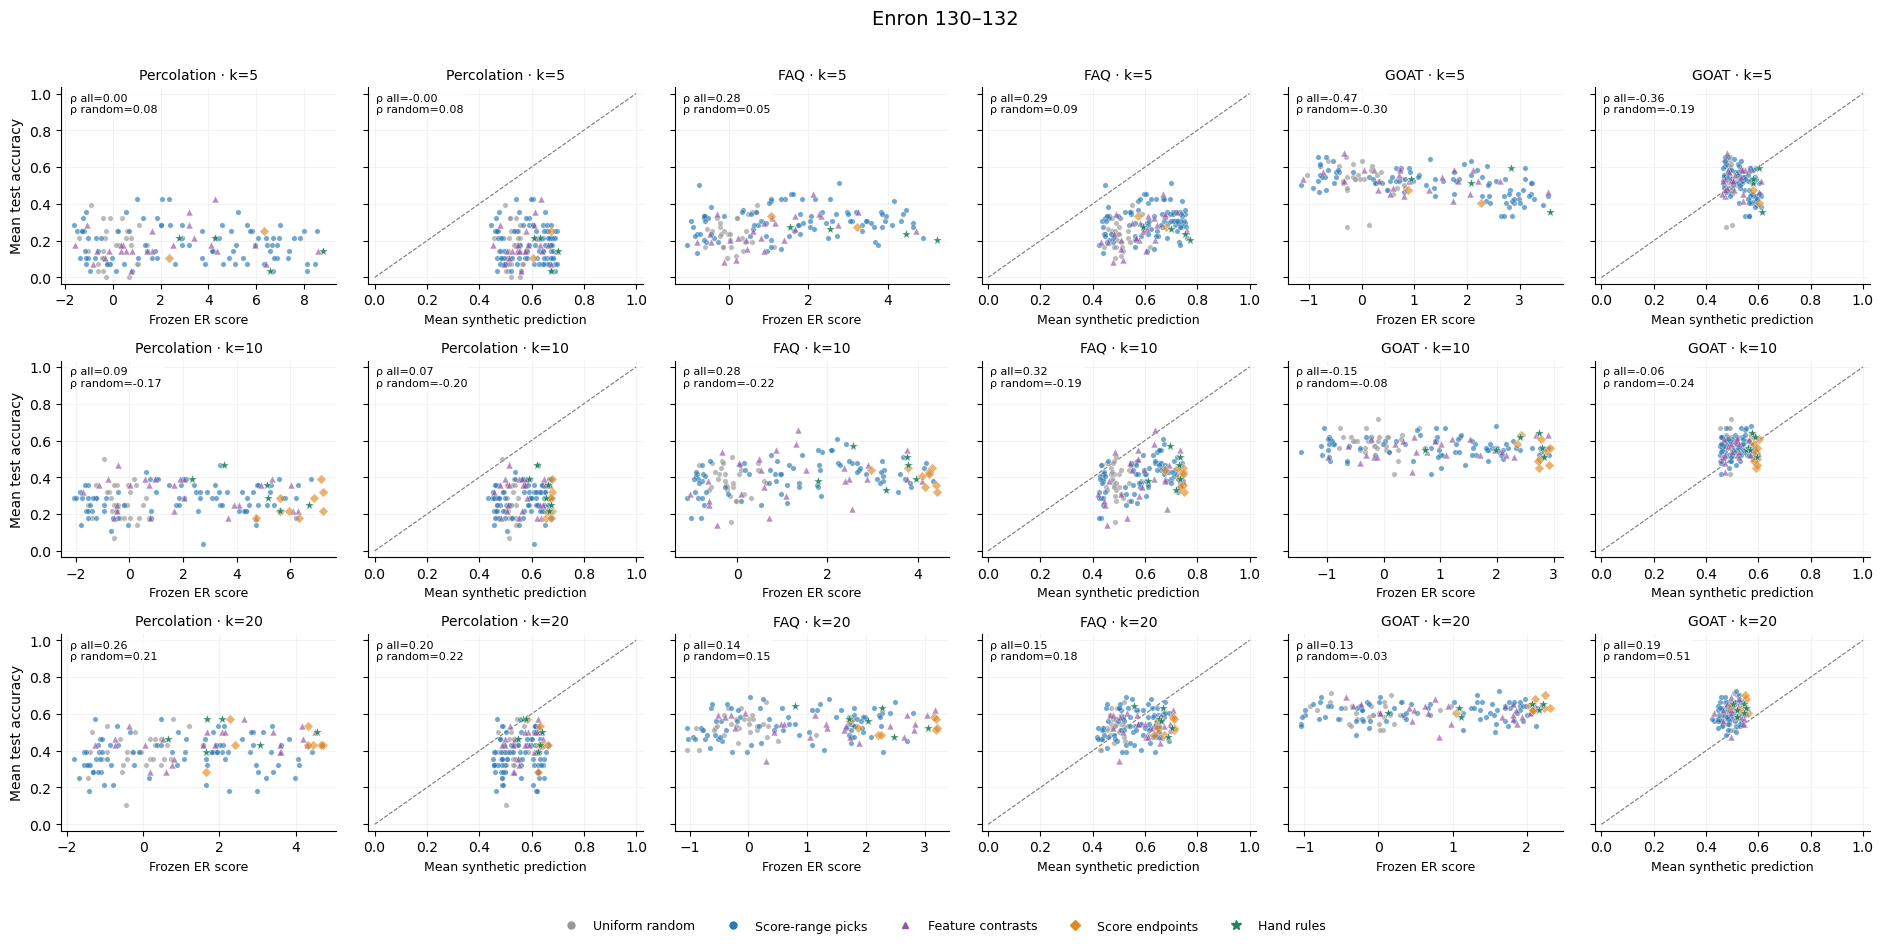

In [6]:
show(A.plot_real_scores(mean, "enron_130_132"), "enron_130_132_scores")

### enron 130 131

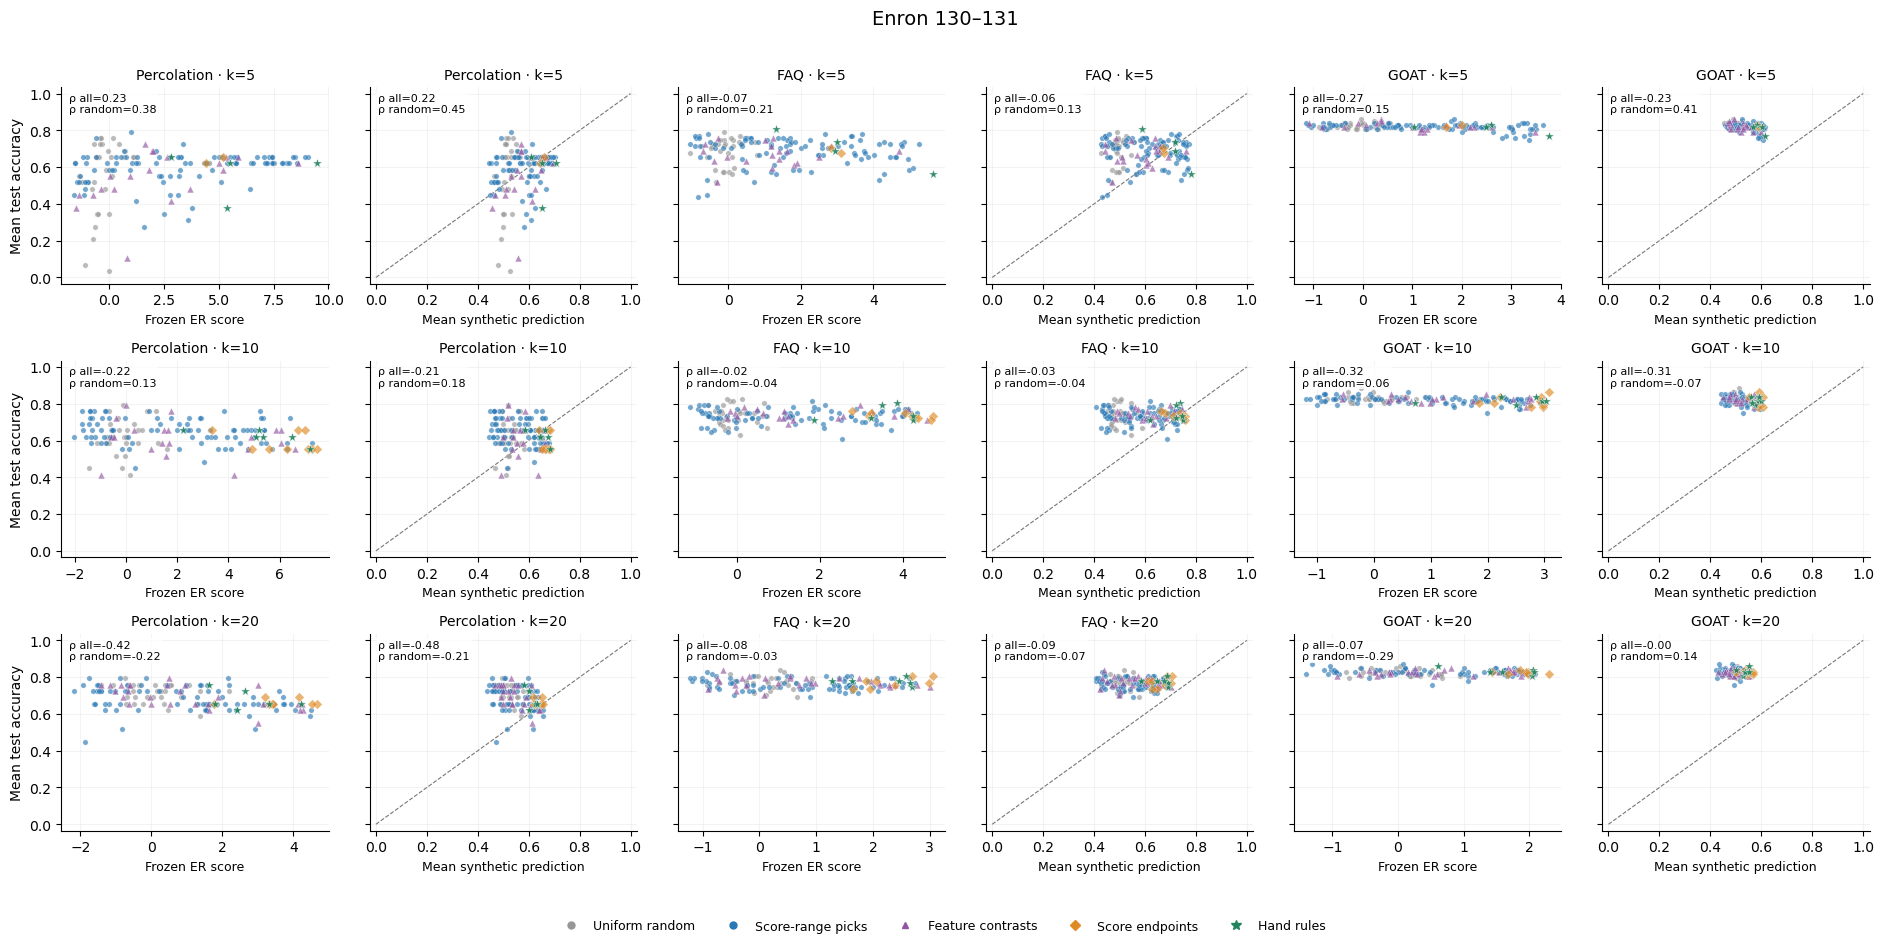

In [7]:
show(A.plot_real_scores(mean, "enron_130_131"), "enron_130_131_scores")

### enron 145 147

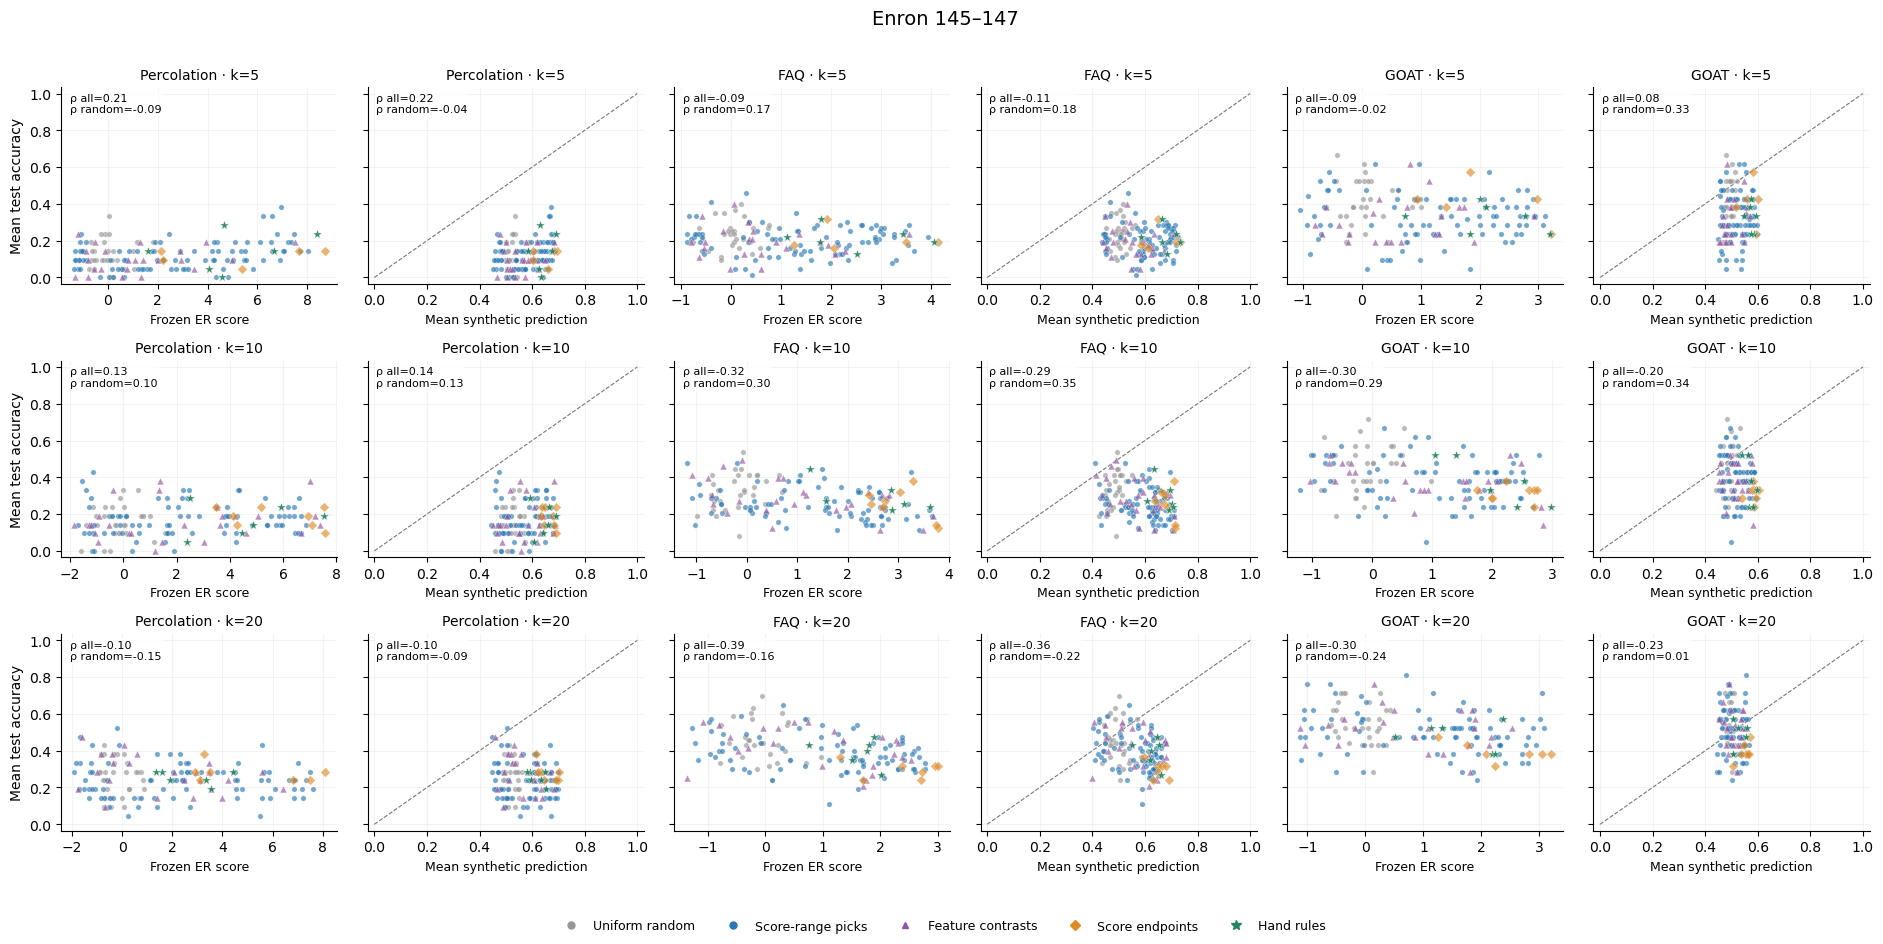

In [8]:
show(A.plot_real_scores(mean, "enron_145_147"), "enron_145_147_scores")

### enron 160 162

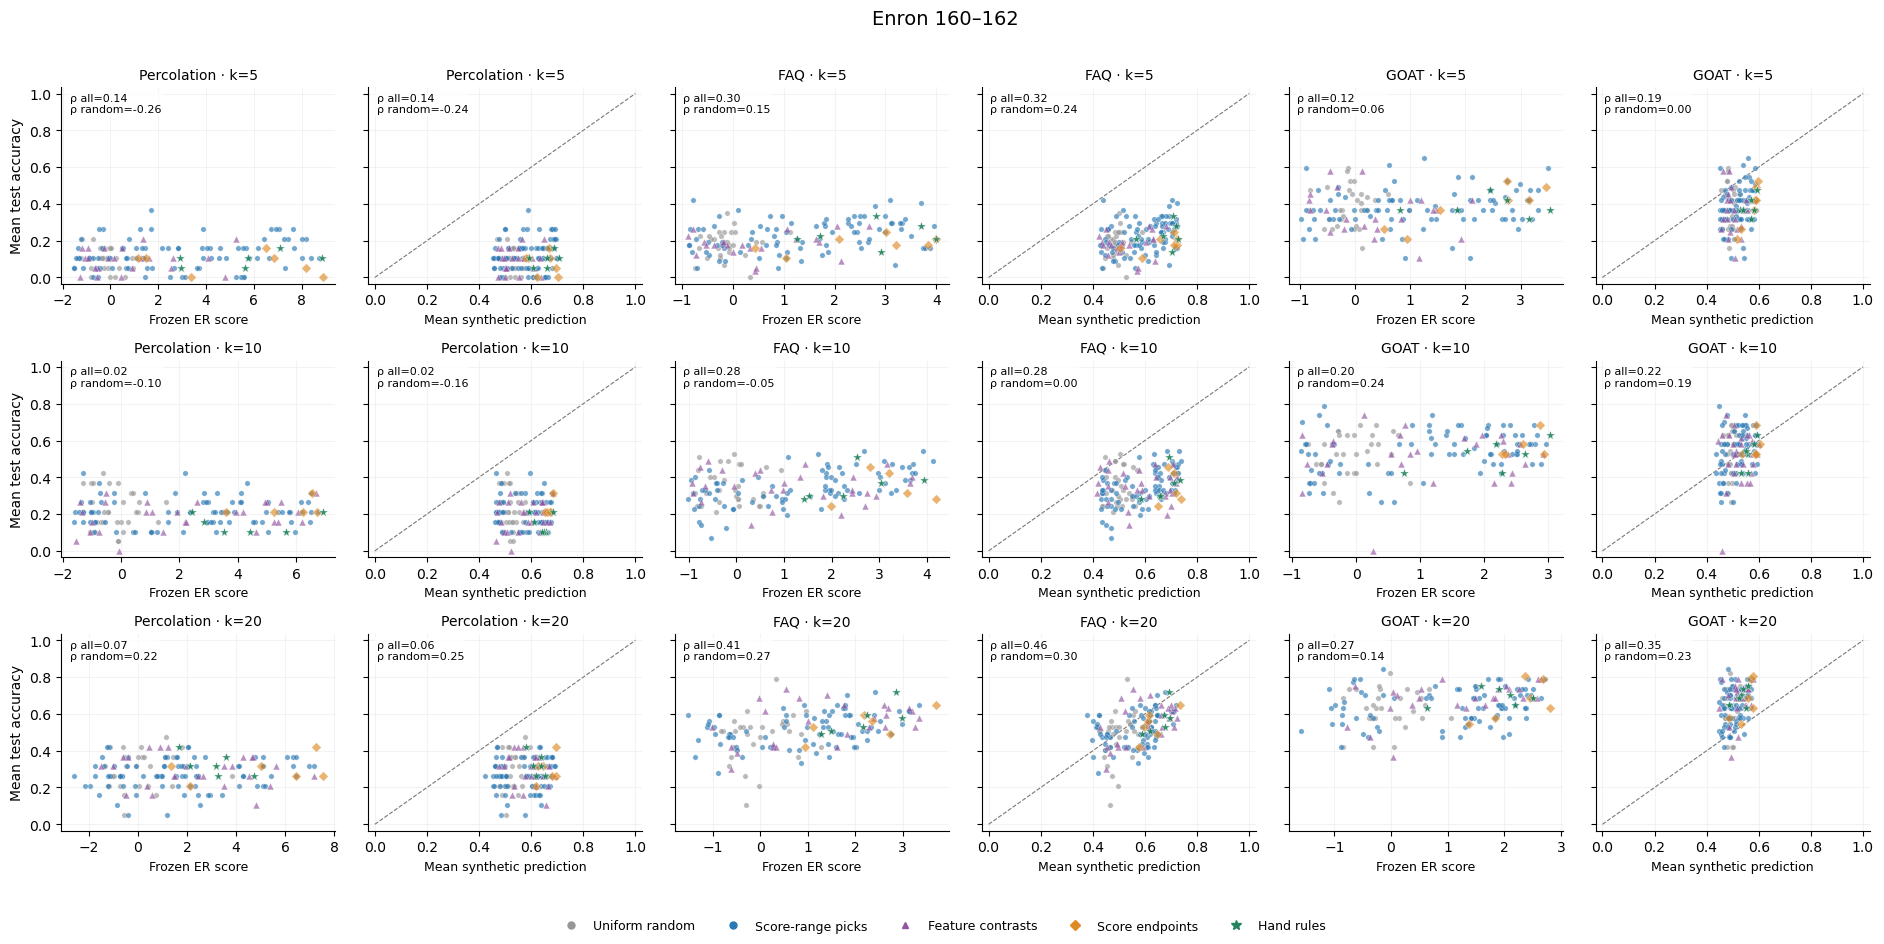

In [9]:
show(A.plot_real_scores(mean, "enron_160_162"), "enron_160_162_scores")

### worm

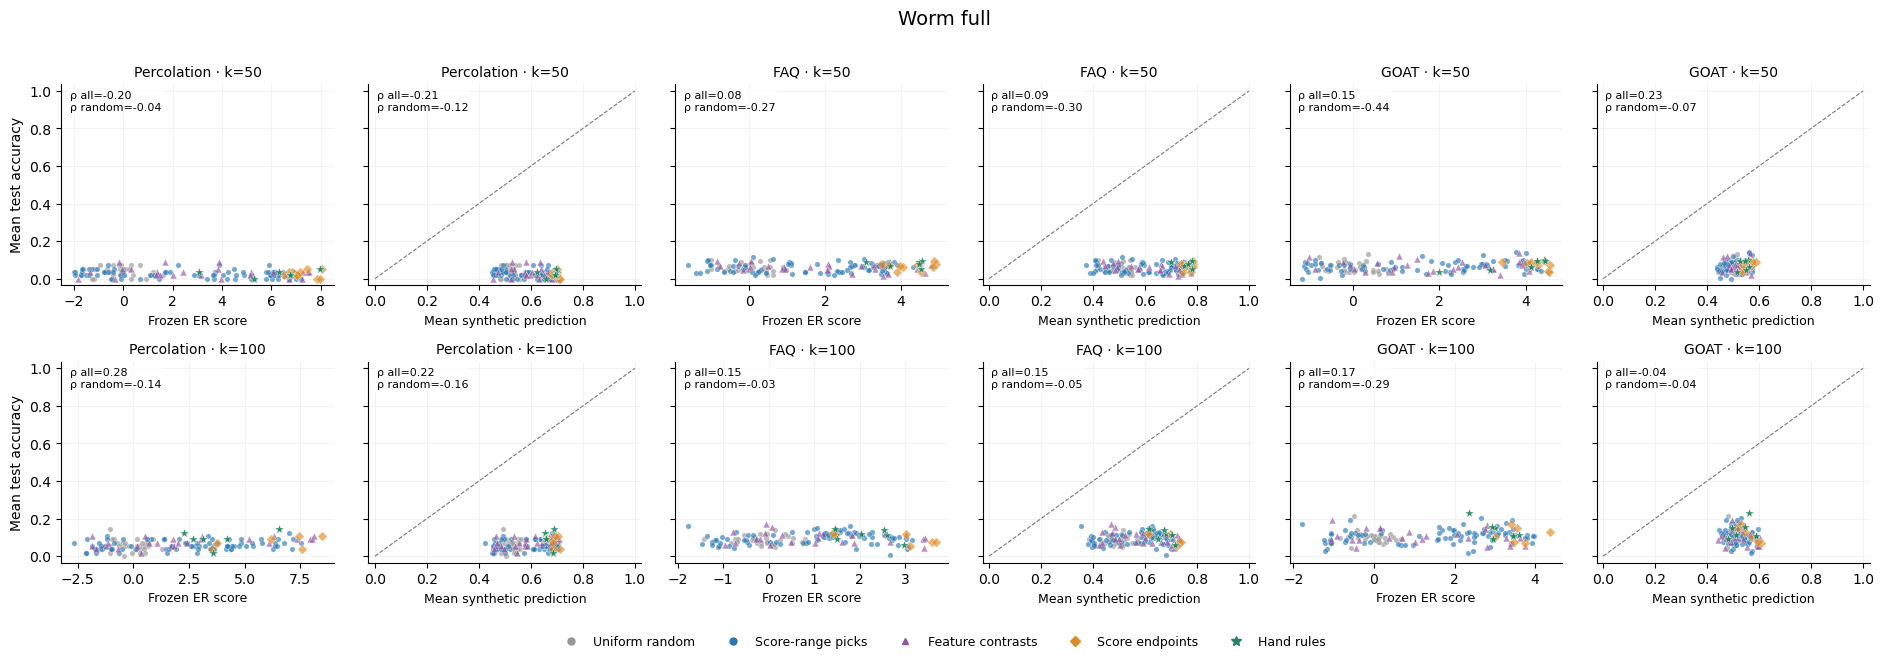

In [10]:
show(A.plot_real_scores(mean, "worm"), "worm_scores")

### worm lcc

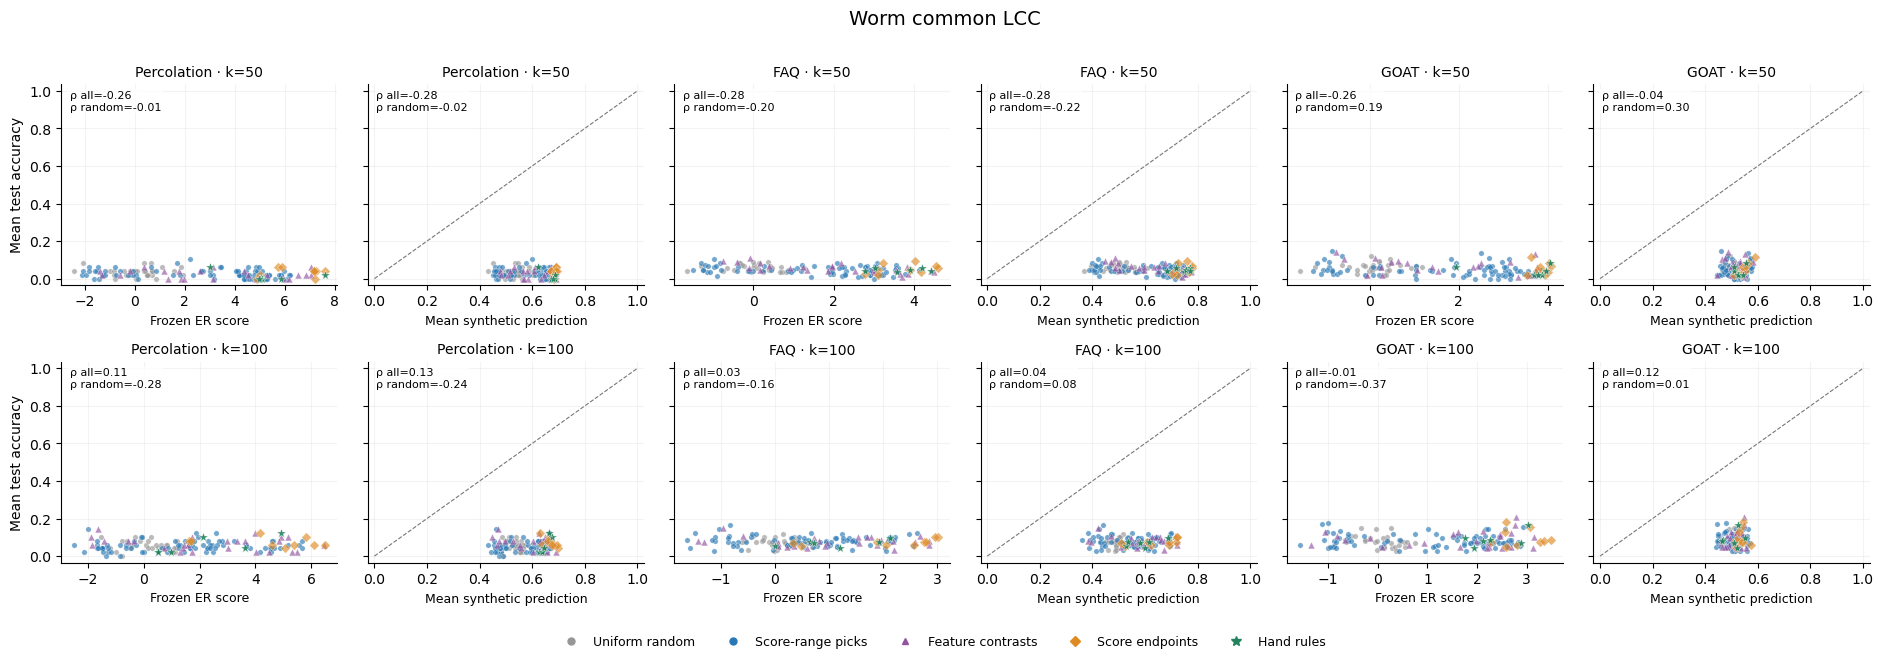

In [11]:
show(A.plot_real_scores(mean, "worm_lcc"), "worm_lcc_scores")

### worm male

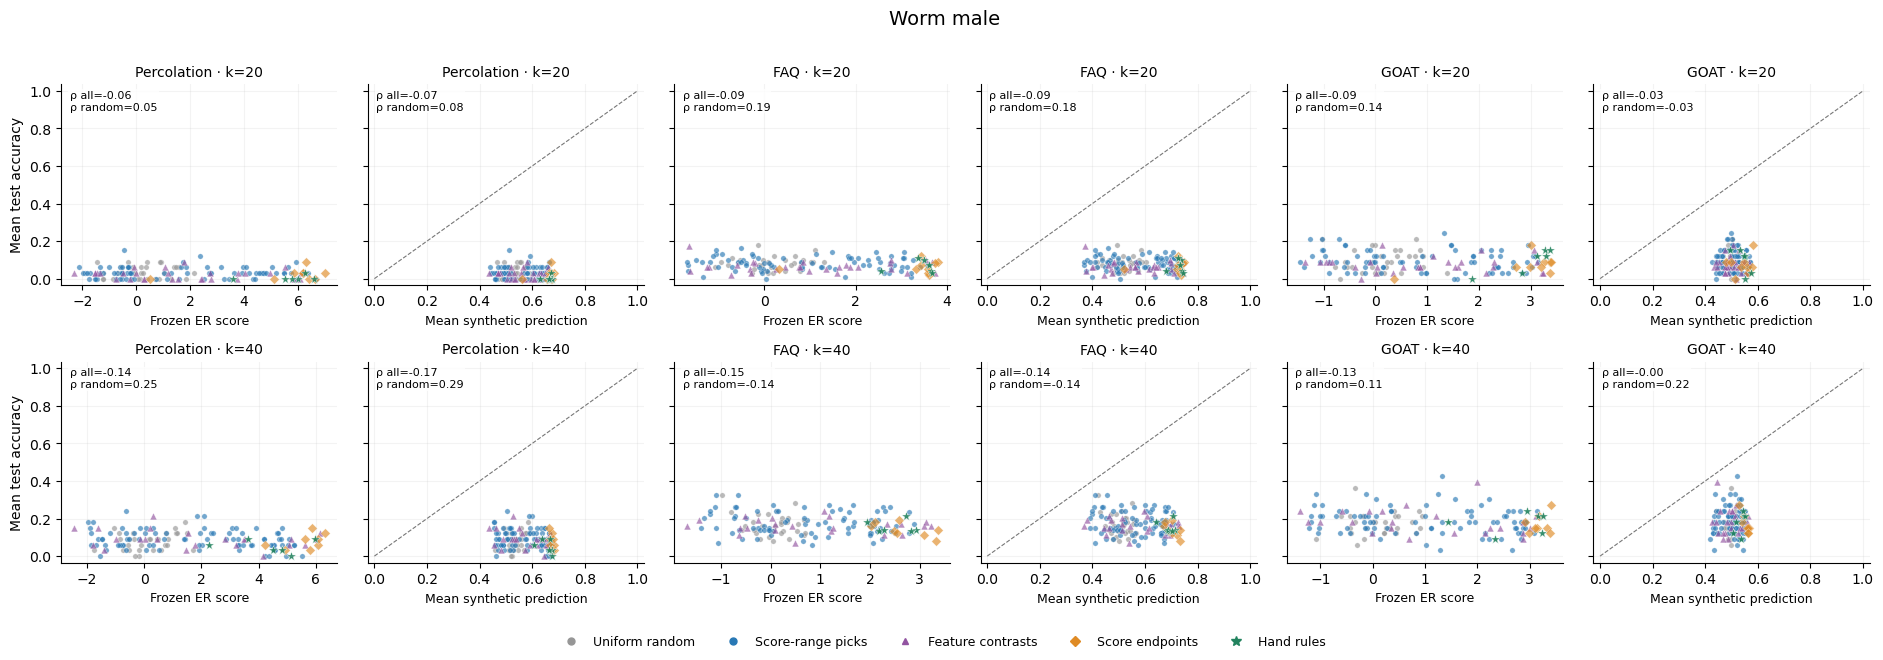

In [12]:
show(A.plot_real_scores(mean, "worm_male"), "worm_male_scores")

## 4. Ranking versus numerical calibration

The heatmaps compare the three frozen references and mean synthetic prediction
within each pair/budget. Prediction MAE and signed bias are separate from rank
correlation: positive bias means predictions are too optimistic on average. These
are descriptive scores over our deliberately sampled banks, not random-population
or cross-validation estimates.

,panel,algorithm,prediction_mae,prediction_bias,source_range_share
0,Enron 130–131 · k=5,percolation,0.096,0.001,0.555
1,Enron 130–131 · k=5,faq,0.125,-0.090,0.973
2,Enron 130–131 · k=5,goat,0.292,-0.292,0.747
3,Enron 130–131 · k=10,percolation,0.105,-0.062,0.504
4,Enron 130–131 · k=10,faq,0.154,-0.148,0.941
5,Enron 130–131 · k=10,goat,0.303,-0.303,0.726
6,Enron 130–131 · k=20,percolation,0.136,-0.131,0.553
7,Enron 130–131 · k=20,faq,0.207,-0.207,0.985
8,Enron 130–131 · k=20,goat,0.323,-0.323,0.729
9,Enron 130–132 · k=5,percolation,0.402,0.402,0.565


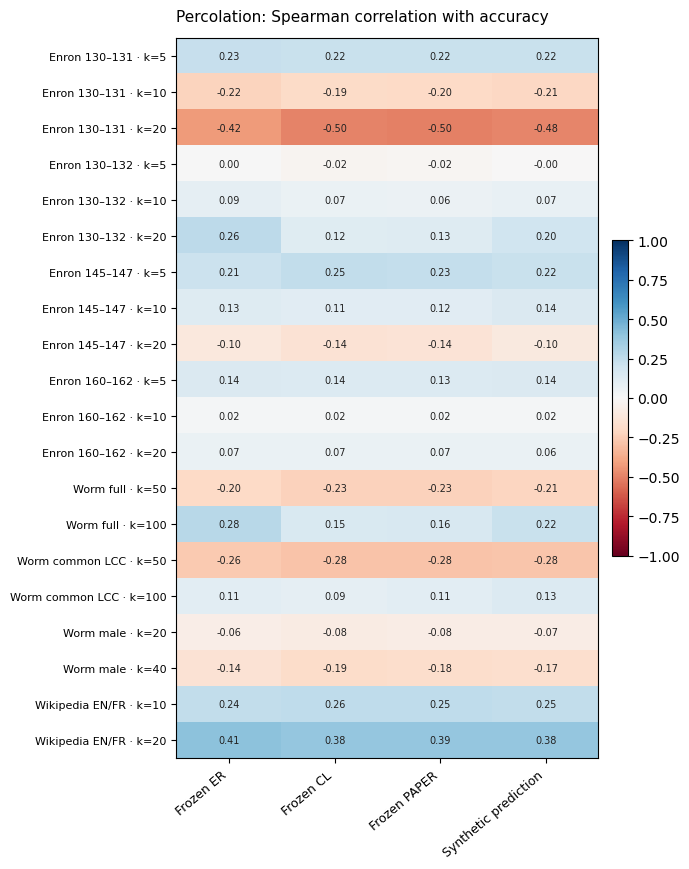

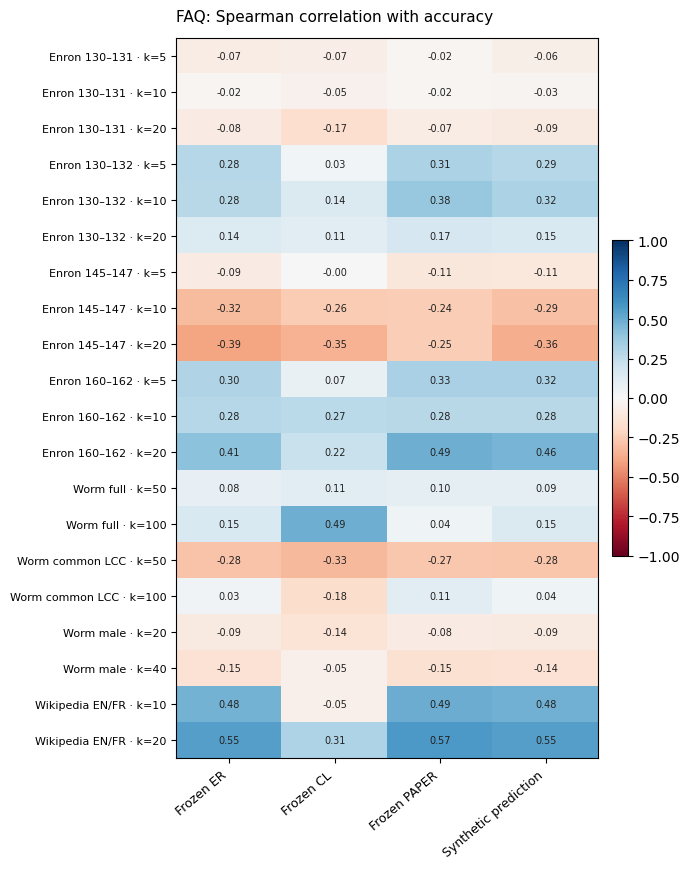

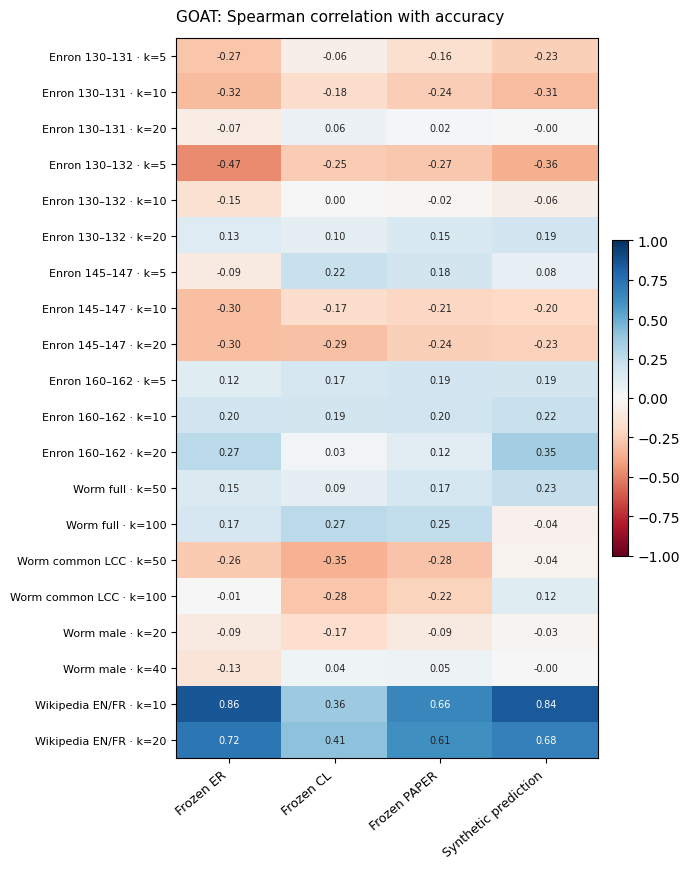

In [13]:
display(scores[["panel", "algorithm", "prediction_mae", "prediction_bias", "source_range_share"]])
for algorithm in A.ALGORITHMS:
    show(A.plot_rank_summary(scores, algorithm), f"{algorithm}_score_correlations")

## 5. Does a score select a good set? How do individual source models transfer?

Every rule is included, especially **clustered**. Frozen and learned policies pick
the highest-scoring set in this common evaluated bank; they do not claim a global
optimum or reproduce the original selector's different search procedure. Mean
prediction picks are unrestricted and their source-range shares are retained in
the CSV. A heatmap value of 0.10 means a ten-percentage-point gain over the uniform
controls' mean on that same pair/budget/algorithm.

Individual source policies prefer sets inside that source's saved training guard;
if none are in range they fall back to the full bank and record that fact. The
ensemble policy does not apply such a single-source guard. Source comparisons are
exploratory, not a justification to choose a source using these evaluation labels.
The hindsight best-observed set is exported separately as `oracle` and is excluded
from policy heatmaps.

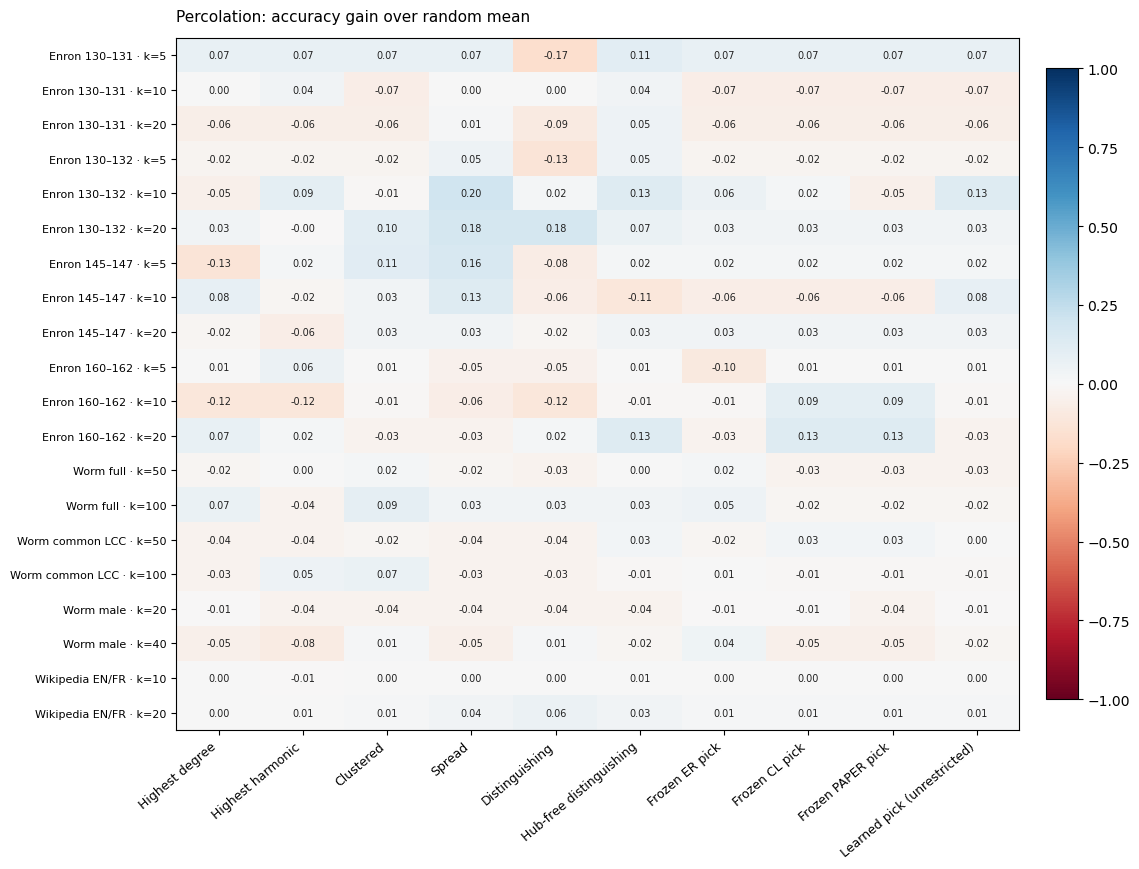

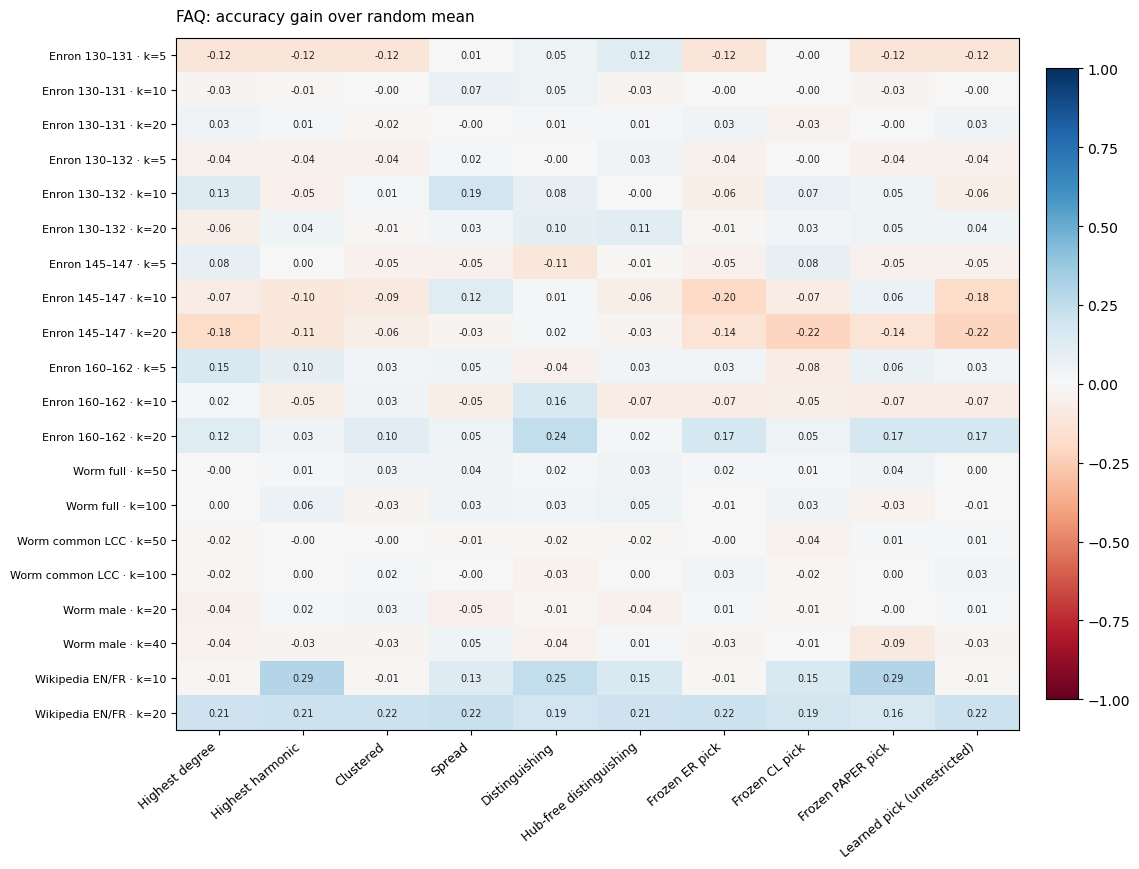

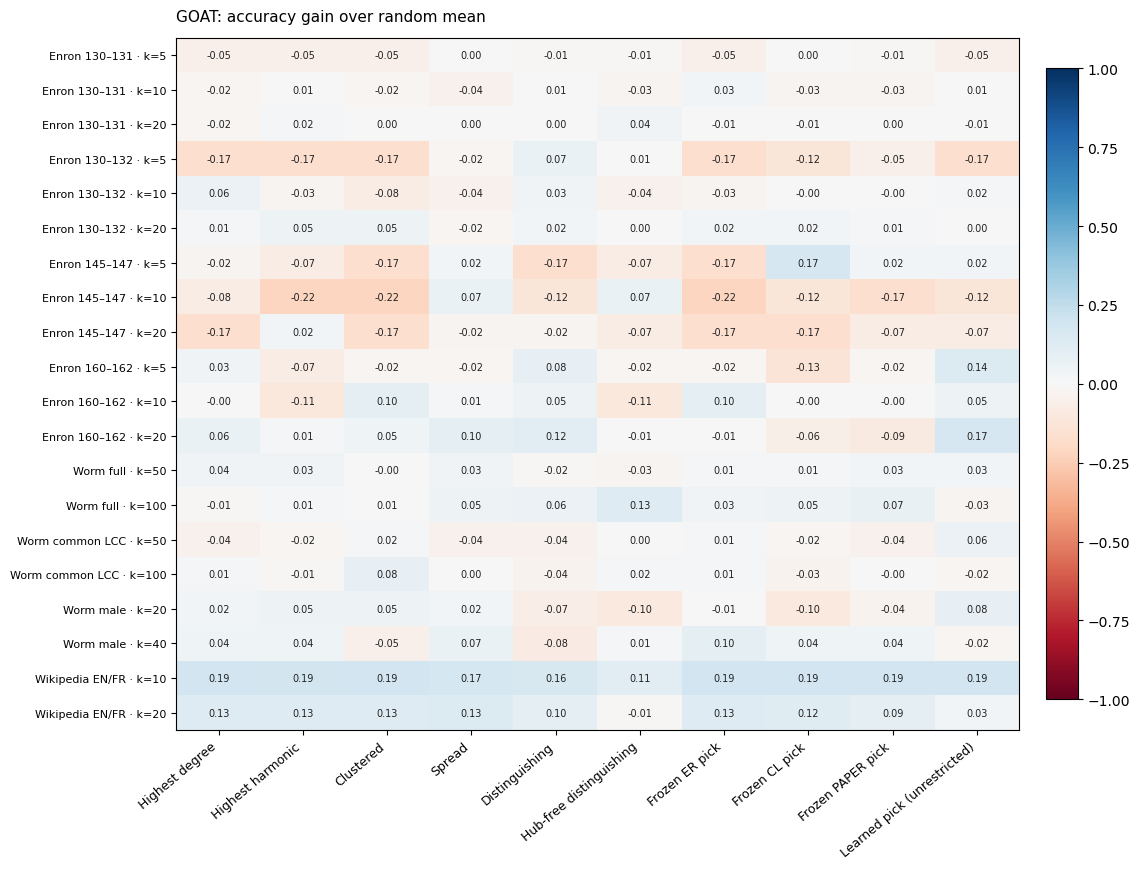

banks  median_rho  median_mae  median_bias  median_pick_gain  mean_in_range_share  range_fallbacks
algorithm   source                                                                                                                                    
faq         chung_lu/faq/d10_rho0.50/k031              20       0.031       0.326        0.325            -0.023                0.954                0
            chung_lu/faq/d16_rho0.30/k107              20       0.008       0.231        0.141            -0.016                0.949                0
            chung_lu/faq/d32_rho0.30/k053              20      -0.016       0.273        0.247            -0.000                0.950                0
            paper_pa/faq/d08_rho0.50/k022              20       0.081       0.465        0.464             0.006                0.943                0
            paper_pa/faq/d16_rho0.30/k053              20       0.079       0.378        0.378            -0.005                0.956                0
            paper_pa/faq/d32_rho0.30/k048              20       0.053       0.413        0.410            -0.007                0.956                0
            sparse_er/faq/d08_rho0.50/k058             20       0.062       0.305        0.302            -0.007                0.957                0
            sparse_er/faq/d16_rho0.30/k143             20       0.048       0.375        0.375             0.024                0.873                0
            sparse_er/faq/d32_rho0.30/k071             20       0.039       0.299        0.272             0.010                0.913                0
goat        chung_lu/goat/d10_rho0.40/k047             20       0.034       0.159        0.001            -0.005                0.899                0
            chung_lu/goat/d10_rho0.50/k012             20      -0.029       0.214        0.205            -0.002                0.923                0
            chung_lu/goat/d16_rho0.30/k076             20      -0.050       0.229       -0.040            -0.005                0.287                0
            paper_pa/goat/d08_rho0.40/k007             20       0.117       0.187       -0.097            -0.021                0.870                0
            paper_pa/goat/d08_rho0.50/k003             20      -0.049       0.276        0.090            -0.001                0.719                0
            paper_pa/goat/d16_rho0.30/k036             20      -0.071       0.403        0.403            -0.005                0.608                0
percolation chung_lu/percolation/d10_rho0.70/k006      20       0.049       0.541        0.540             0.003                0.888                0
            chung_lu/percolation/d16_rho0.40/k054      20       0.032       0.482        0.482            -0.003                0.615                0
            chung_lu/percolation/d32_rho0.30/k089      20       0.054       0.389        0.389             0.009                0.287                0
            paper_pa/percolation/d08_rho0.70/k003      20      -0.021       0.265        0.263            -0.003                0.652                0
            paper_pa/percolation/d16_rho0.40/k024      20       0.063       0.373        0.372             0.006                0.703                0
            paper_pa/percolation/d32_rho0.30/k047      20       0.049       0.402        0.402             0.007                0.284                0
            sparse_er/percolation/d08_rho0.70/k013     20       0.064       0.463        0.461             0.006                0.901                0
            sparse_er/percolation/d16_rho0.40/k051     20       0.024       0.441        0.441             0.007                0.287                0
            sparse_er/percolation/d32_rho0.30/k093     20       0.037       0.543        0.543             0.013                0.287                0

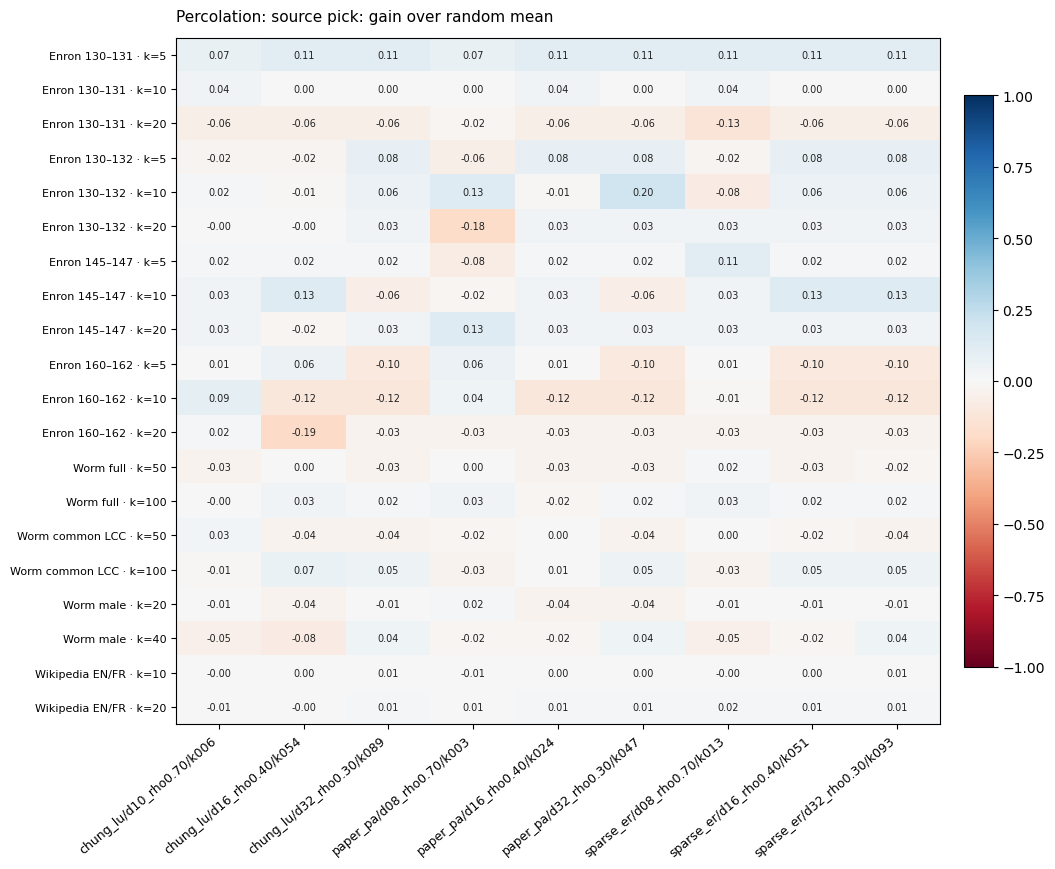

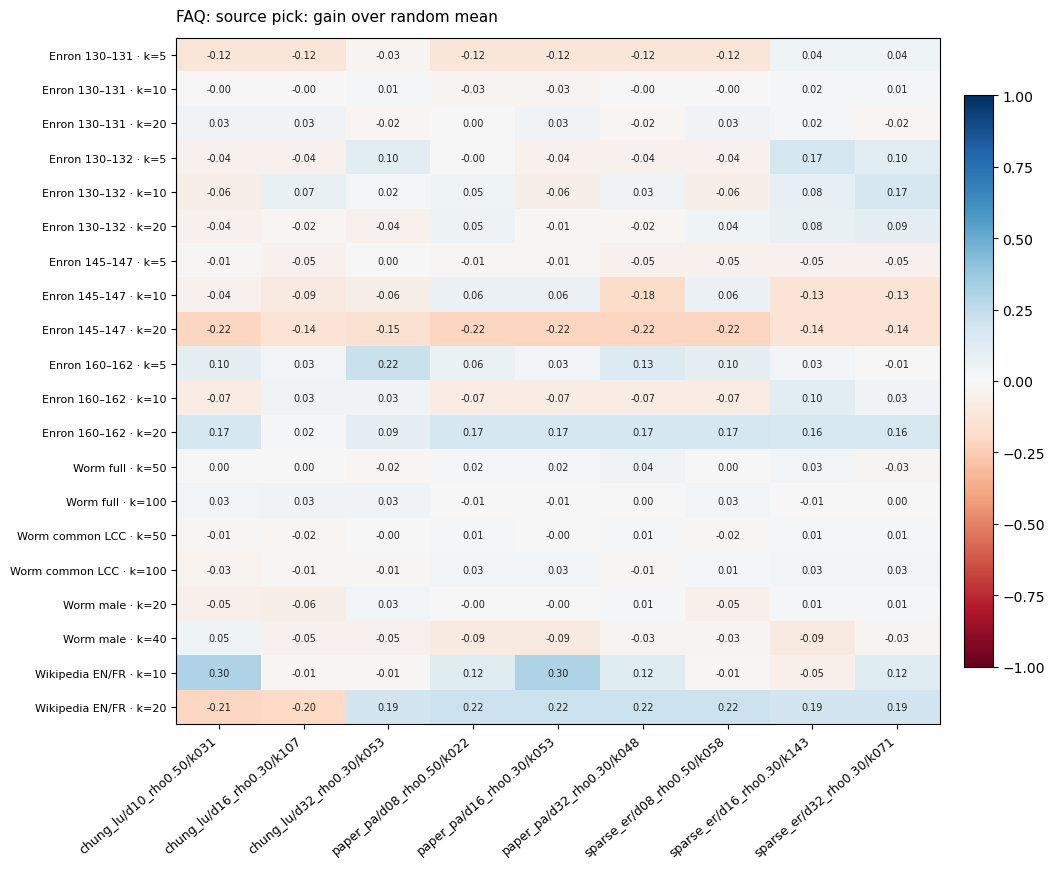

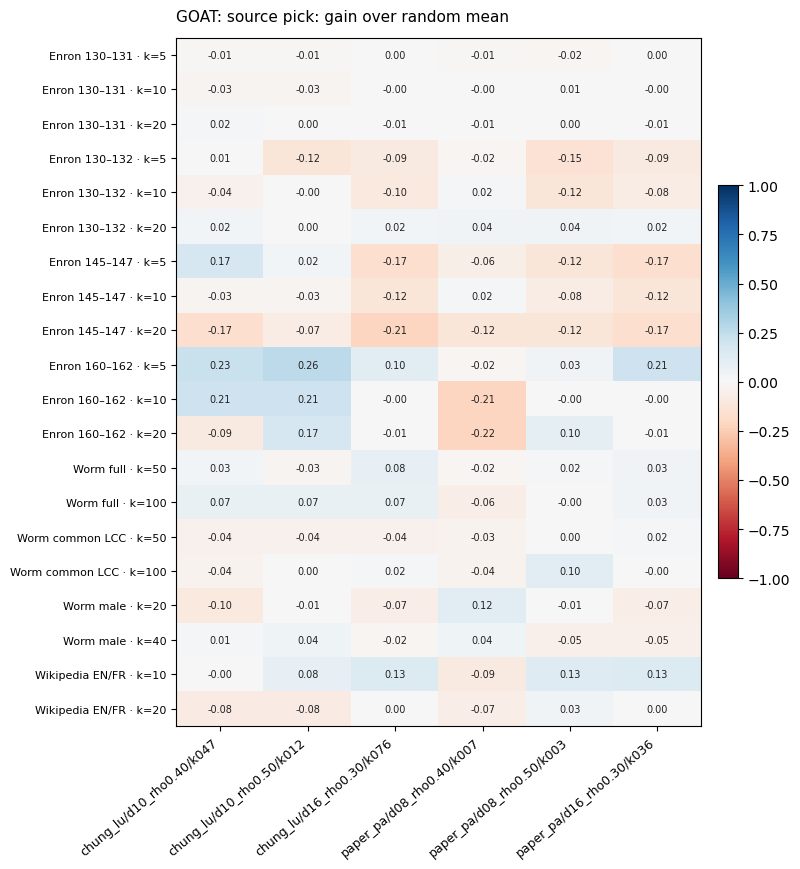

In [14]:
for algorithm in A.ALGORITHMS:
    show(A.plot_policy_summary(policies, algorithm), f"{algorithm}_policy_gains")
source_summary = sources.groupby(["algorithm", "source"]).agg(
    banks=("bank_id", "size"), median_rho=("rho", "median"), median_mae=("mae", "median"),
    median_bias=("bias", "median"), median_pick_gain=("pick_gain", "median"),
    mean_in_range_share=("in_range_share", "mean"), range_fallbacks=("range_fallback", "sum"))
display(source_summary)
for algorithm in A.ALGORITHMS:
    show(A.plot_sources(sources, algorithm, "pick_gain"), f"{algorithm}_individual_source_gains")

## 6. Which individual features track performance?

Each heatmap entry is a within-bank Spearman correlation across all unique seed
sets. Grey cells are undefined because a feature or the outcome is constant. All
core features use the algorithm's own definition, including distance-uniqueness
cap 2 for FAQ and cap 3 for percolation/GOAT. Coverage ≥2/≥3 and signature
collision features were computed on A during collection.

These correlations are exploratory and include intentionally constructed sets.
They do not establish that a feature adds value beyond degree; the saved contrasts
in the next section address that question more directly.

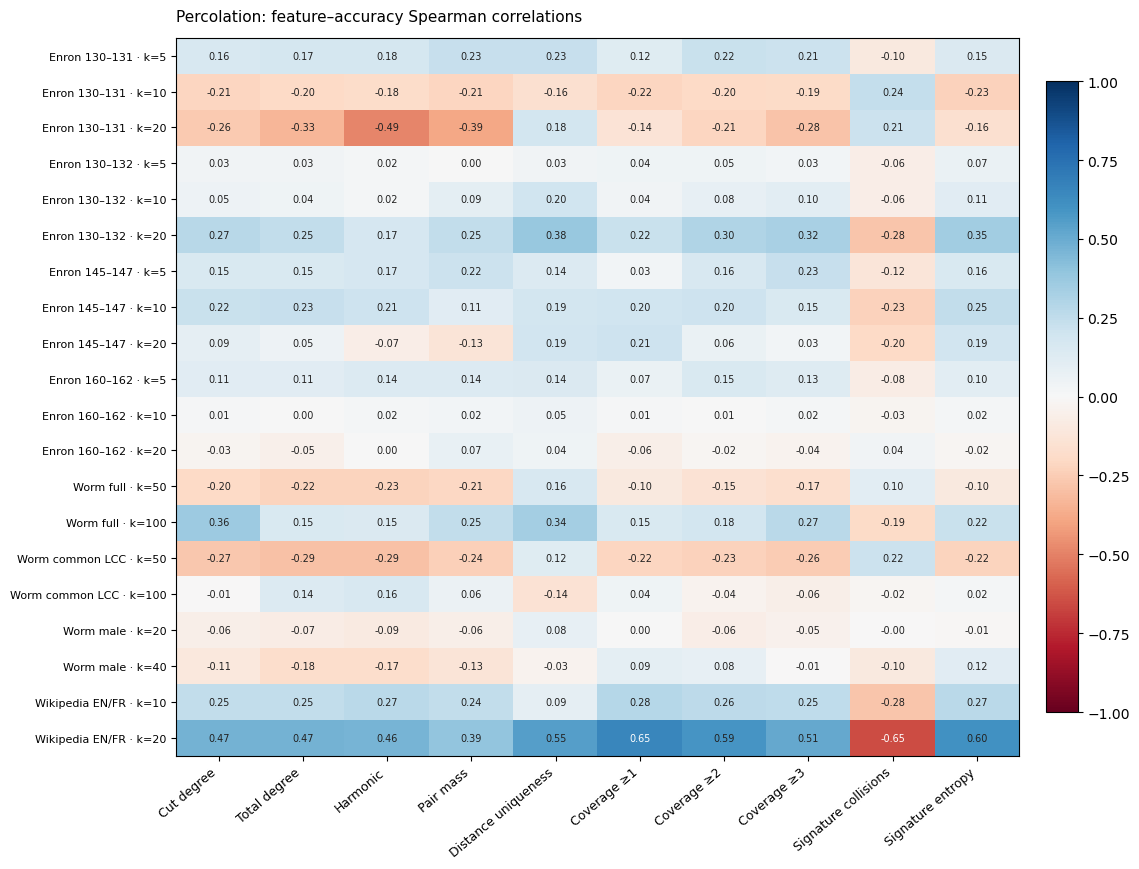

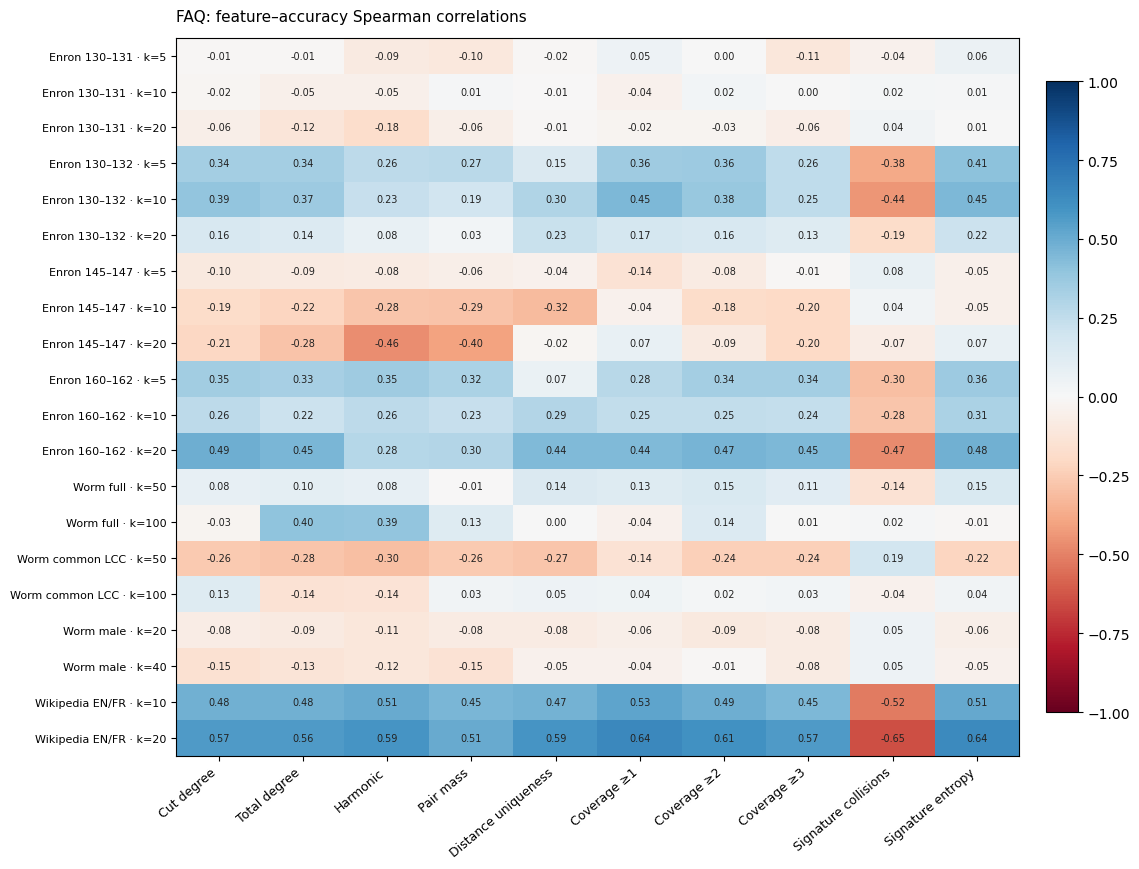

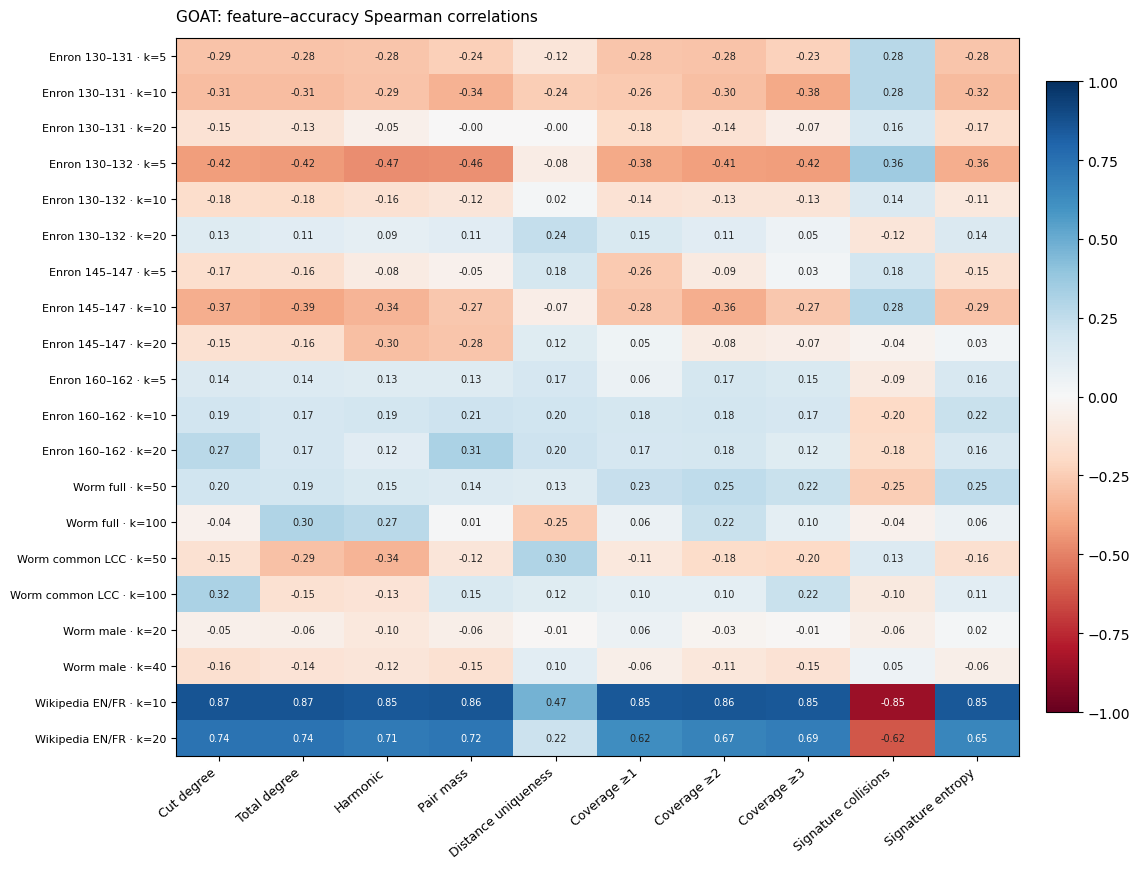

In [15]:
for algorithm in A.ALGORITHMS:
    show(A.plot_feature_summary(features, algorithm), f"{algorithm}_feature_correlations")

Two examples in more detail. Change `FEATURE_ALGORITHM`, case, or budget to inspect
other panels; all cases/algorithms are included in the heatmaps above.

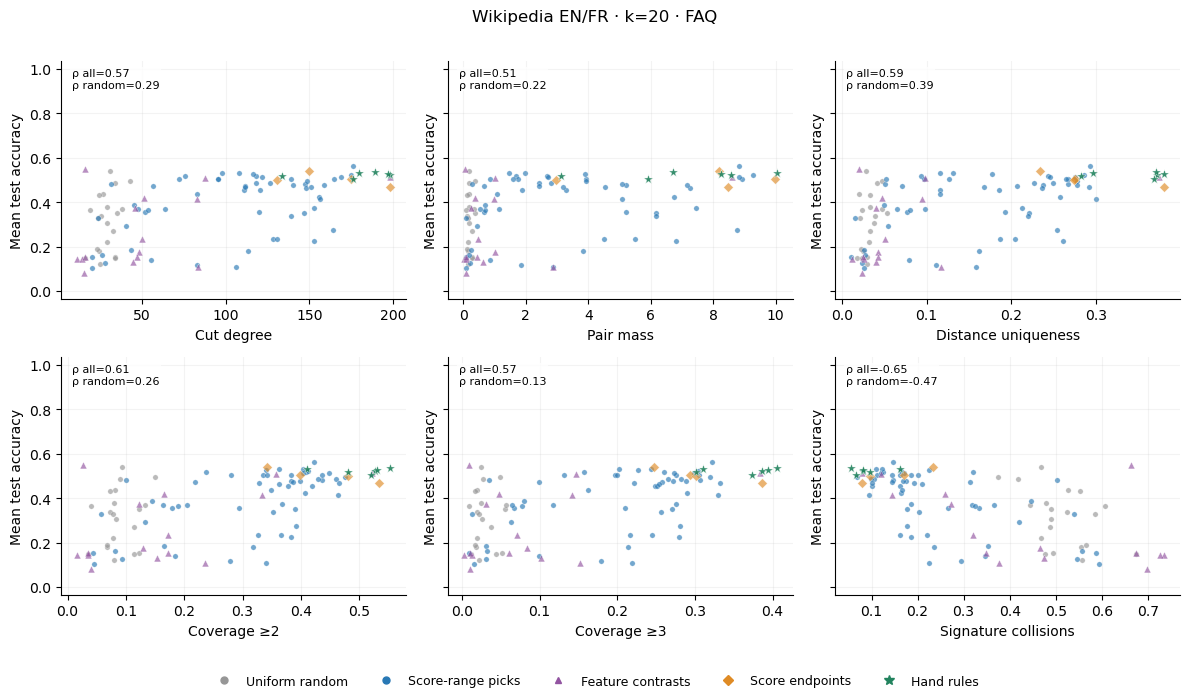

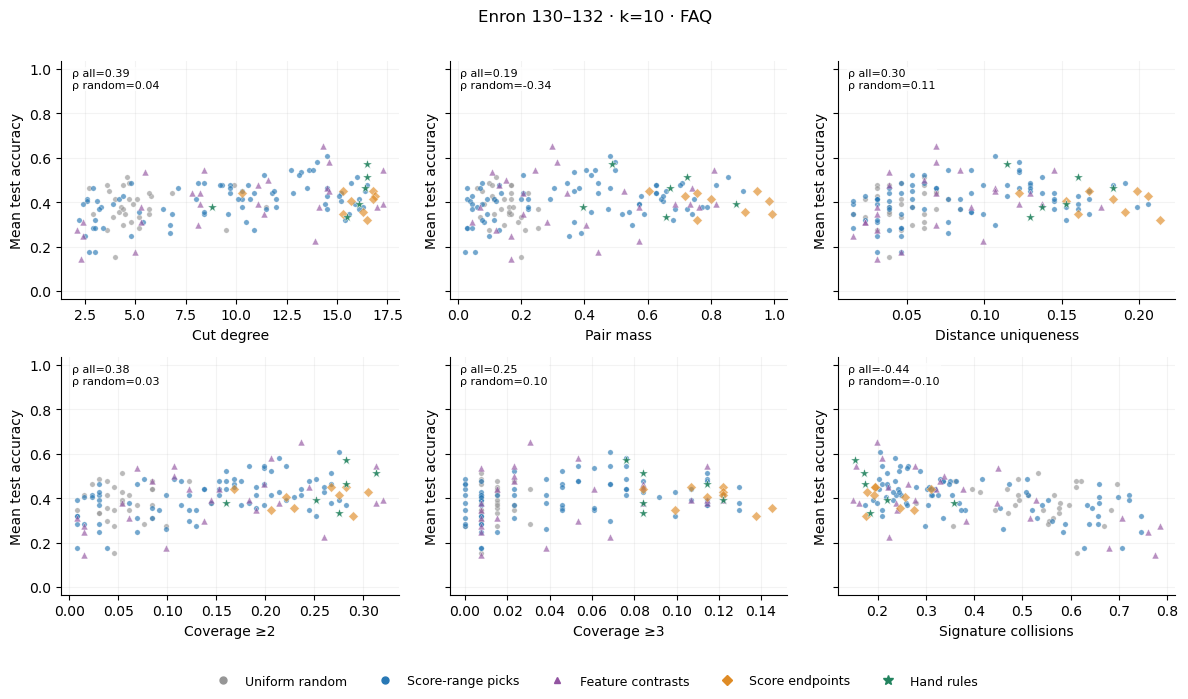

In [16]:
FEATURE_ALGORITHM = "faq"
for case, budget in [("wikipedia", 20), ("enron_130_132", 10)]:
    show(A.plot_feature_scatter(mean, case, budget, FEATURE_ALGORITHM),
         f"{case}_k{budget:03d}_{FEATURE_ALGORITHM}_features")

## 7. Feature contrasts at similar cut degree

These low/high contrasts were selected on A before matching was run. Plot only
pairs whose actual cut-degree difference is at most 0.25 random-pool SD; the full
table retains all pairs and their degree gaps. A point above zero means the
higher-feature set performed better. No significance intervals are fitted.

Degree matching is approximate, and other features can change simultaneously.
Contrasts within a bank can share sets and are not independent graph replicates.
For uniqueness, the x-axis follows the cap used to construct the contrast: cap 3
on shared real banks, and the cell's own cap on synthetics. The exported table
also gives the feature difference under the matching algorithm's cap.

contrasts  mean_accuracy_difference  median_accuracy_difference  fraction_positive  median_degree_gap_z
algorithm   feature                                                                                                            
faq         coverage           79                     0.039                       0.020              0.633                0.105
            pair_mass          81                    -0.036                      -0.027              0.247                0.089
            uniqueness         92                     0.028                       0.024              0.554                0.111
goat        coverage           79                     0.014                       0.014              0.570                0.105
            pair_mass          81                     0.005                       0.000              0.407                0.089
            uniqueness         92                     0.008                       0.000              0.478                0.111
percolation coverage           79                     0.022                       0.000              0.456                0.105
            pair_mass          81                    -0.003                      -0.020              0.370                0.089
            uniqueness         92                     0.027                       0.016              0.511                0.111

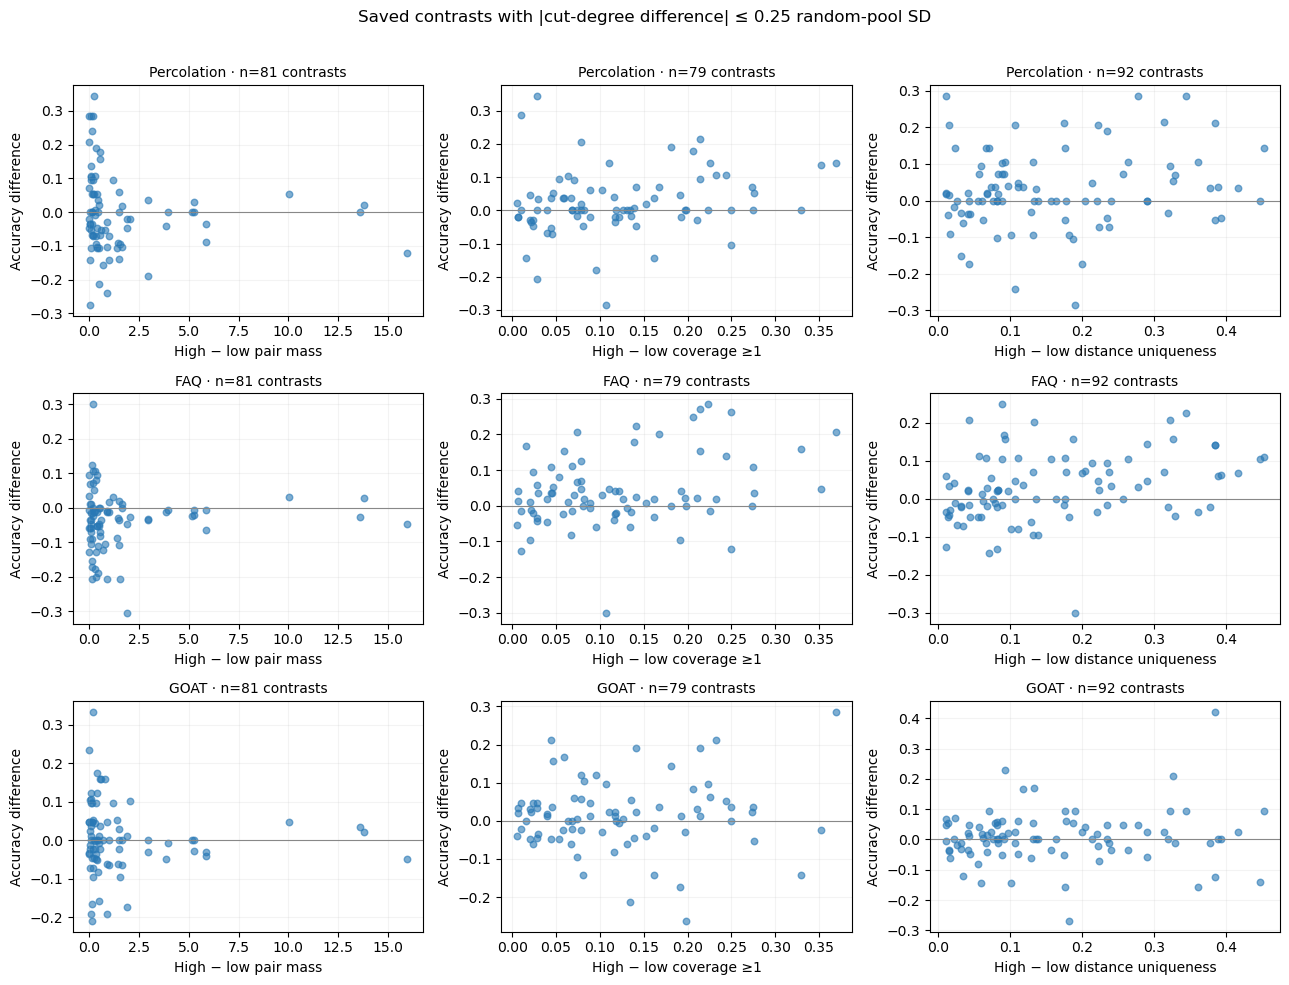

In [17]:
MAX_DEGREE_GAP_Z = 0.25
close = contrasts[contrasts.degree_z_gap.le(MAX_DEGREE_GAP_Z)]
display(close.groupby(["algorithm", "feature"]).agg(
    contrasts=("accuracy_delta", "size"), mean_accuracy_difference=("accuracy_delta", "mean"),
    median_accuracy_difference=("accuracy_delta", "median"),
    fraction_positive=("accuracy_delta", lambda s: s.gt(0).mean()),
    median_degree_gap_z=("degree_z_gap", "median")))
show(A.plot_contrasts(contrasts, MAX_DEGREE_GAP_Z), "degree_band_contrasts")

## 8. Solver convergence and sensitivity

All valid outcomes are retained in the main analyses: the experiment measures
performance under its fixed solver budget. Below, recompute correlations on the
subset of sets for which every evaluated FAQ/GOAT run converged. That subset can
be structurally different, so this is a diagnostic rather than a corrected result.
Percolation is omitted here because its `converged` flag means a complete matching,
not numerical optimizer convergence. Repeated solver runs or B draws do not
increase the number of independent A graphs.

In [18]:
display(convergence.groupby("algorithm")[["runs", "not_converged_runs"]].sum())
display(convergence.loc[convergence.not_converged_runs.gt(0)].drop(columns="bank_id"))

,runs,not_converged_runs
algorithm,,
faq,8500,944
goat,8500,0


,algorithm,panel,runs,not_converged_runs,not_converged_share,sets_all_runs_converged,sets_total,rho_frozen_all,rho_frozen_converged_subset,rho_learned_all,rho_learned_converged_subset
0,faq,Enron 130–131 · k=5,450,162,0.360,39,150,-0.071,0.144,-0.060,0.156
2,faq,Enron 130–131 · k=10,450,270,0.600,21,150,-0.020,-0.254,-0.030,-0.271
4,faq,Enron 130–131 · k=20,450,350,0.778,2,150,-0.083,NaN,-0.086,NaN
6,faq,Enron 130–132 · k=5,450,7,0.016,143,150,0.284,0.259,0.289,0.259
8,faq,Enron 130–132 · k=10,450,8,0.018,142,150,0.277,0.284,0.316,0.319
10,faq,Enron 130–132 · k=20,450,27,0.060,124,150,0.140,0.054,0.154,0.092
12,faq,Enron 145–147 · k=5,450,1,0.002,149,150,-0.085,-0.085,-0.106,-0.106
16,faq,Enron 145–147 · k=20,450,5,0.011,145,150,-0.392,-0.404,-0.361,-0.369
18,faq,Enron 160–162 · k=5,450,3,0.007,147,150,0.302,0.297,0.322,0.321
20,faq,Enron 160–162 · k=10,450,6,0.013,144,150,0.281,0.307,0.278,0.302


## 9. Exports and interpretation

Every displayed figure is exported as PNG and PDF. CSV tables contain the full
inventory, per-seed means, score diagnostics, feature correlations, policy picks,
individual source-model diagnostics, contrasts and convergence results. The
collector's raw files and saved model snapshots remain the inputs for this notebook.

Read ranking, calibration and selection performance separately. A high correlation
does not guarantee a good top pick, and a useful ranking need not predict absolute
accuracy well. The broad bank deliberately changes the sampled feature distribution.
Generalization claims require additional A graphs and untouched real pairs.

In [19]:
A.export_tables(EXPORT,
    inventory=A.inventory(data), per_seed_mean=mean, score_coverage=coverage,
    sampling_intervals=data.coverage,
    score_diagnostics=scores, feature_correlations=features, policy_results=policies,
    individual_sources=sources, degree_contrasts=contrasts, convergence=convergence,
    overview=summary.reset_index())
print("CSV tables:", EXPORT)
print("PNG/PDF figures:", FIGURES)

CSV tables: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/score_range_analysis/real
PNG/PDF figures: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/score_range_analysis/real/figures
